# Welcome Back!

I hope you had a good break! This tutorial notebook is the logical successor to [the VQE tutorial](../05-algorithms.ipynb) and will cover the diagonalization of a molecular Hamiltonian. We could use dihydrogen again, but I hope you're feeling as adventurous as I am! We'll use a precomputed dataset with a host of molecular data, and once the workflow clicks for you, you can keep exploring! 

Also, this notebook **requires a Python Version <= 3.11.x,** because of some dependencies that are not yet compatible with Python 3.12.x and higher. Apologies for any inconvenience, I tried really hard with my own 3.12.6 version. I strongly recommend using a virtual environment manager like `venv` or `conda` to create an isolated environment with the required Python version for this notebook.

Remember to install the necessary dependencies, which include `matplotlib`, `qiskit`, `qiskit_ibm_runtime`, `qiskit_aer`, `time` and `ticker`. Don't forget to set the correct Python version in your environment as your JuPyter kernel.

Before we begin, I admit there were a few lapses in my coverage of VQE, especially considering that it is one of the most important algorithms in quantum chemistry, plus it serves as a jumping off point for many other problems therein. Primarily, while VQE and its physical motivation were discussed in detail, an important practical aspect was deliberately simplified.

In particular, the energies $$E[\psi] = \frac{\langle \psi | \hat{\mathscr H} | \psi \rangle}{\langle \psi | \psi \rangle}$$ were evaluated using Qiskit’s Estimator primitive, which abstracts away the measurement process: 

`pub = (ansatz, [hamiltonian], [params])`

`result = estimator.run([pub]).result()`

On hardware, this quantity is not computed directly but obtained through repeated measurements (*sampling*) of Pauli operators (Paulis is a fun shorthand I like to use). Notably, expectation values are **statistical quantities,** not exact outputs, and each term in the Hamiltonian must be measured individually or in commuting groups.

Other things I forgot to mention but were silently implied in the 5-notebook series were that
1. Measurement outcomes are inherently probabilistic, requiring many shots, and
2. The accuracy of results depends on sampling noise and shot count

In this notebook, I'd address these gaps explicitly by showing how expectation values are constructed from measurement data, and how this naturally leads to sample-based and Krylov-based quantum diagonalization methods. Don't worry about these fancy terms, we'll break them down step by step. All you need to know for now is that these methods are powerful tools for finding eigenvalues and eigenvectors of Hamiltonians. Let's dive in!

In [1]:
import numpy as np, matplotlib.pyplot as plt, scienceplots
plt.style.use(['science', 'notebook', 'grid', 'dark_background'])

# OTHER QISKIT IMPORTS

from qiskit import *
from qiskit.visualization import *
from qiskit_ibm_runtime import *
from qiskit_aer import *

from qiskit.circuit import Parameter
from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import n_local, PauliEvolutionGate

import time
from matplotlib import ticker

# DRAW STYLE (default mpl dark), check https://quantum.cloud.ibm.com/docs/en/guides/visualize-circuits and 
# https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.visualization.circuit_drawer for more styles

def draw_circuit(qc):
    return qc.draw(output = 'mpl', style = 'iqp-dark')

# Diagonalization Methods for a Molecular Hamiltonian

Samples. Expectation values... diagonalization. That's pretty much it for *Sample-based Quantum Diagonalization* (SQD). This is in moderate contrast to VQE where we had to worry about ansatz design, optimization, and all that jazz. SQD is more straightforward in that it directly uses measurement data to construct a matrix representation of the Hamiltonian in a chosen basis (usually the Pauli basis), and then diagonalizes this matrix classically to find the eigensolutions.

SQD avoids classical optimization over parameters, but still depends critically on the choice of quantum state preparation and the quality of sampled measurement data.

# Sample-based Quantum Diagonalization (SQD)

More formally, an SQD-based workflow involves

1. Choose a circuit ansatz and apply it on a quantum computer to a reference state,
2. Sample bitstrings from the resulting quantum state, and
3. Run the self-consistent configuration recovery procedure on the bitstrings to obtain the ground state approximation.

Again, we'll break down each of these steps in detail and clear up the jargon. First, we choose a molecule and extract its Hamiltonian. Then, we design a quantum circuit (ansatz) to prepare a trial state. Next, we run this circuit on a quantum device to get measurement outcomes (bitstrings). Finally, we use these bitstrings to construct a matrix representation of the Hamiltonian and diagonalize it classically to find the ground state energy and wavefunction.

I wanted to avoid generating the Hamiltonian from scratch this time, so I found a dataset of molecular Hamiltonians on [Pennylane's](https://pennylane.ai/datasets/collection/qchem) quantum datasets, which provide precomputed electronic structure data for various molecules, which we can directly use in our SQD workflow. Heavy molecules are very... heavy, since they use the full electronic structure Hamiltonian (remember, qubits scale as $2^N$), so I'd recommend sticking with hydrogen or helium molecules.

In [2]:
%pip install --no-cache-dir 'jax[cpu]'
%pip install aiohttp fsspec h5py
%pip install pennylane

Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 548.9/548.9 kB 5.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 7.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [aiohttp]m4/9 [frozenlist]
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 6.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 7.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 7.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.8/5.8 MB 7.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 6.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12/12 [pennylane]12 [pennylane]lightning]
Note: you may need to restart the kernel to use updated packages.


```bibtex
@misc{Utkarsh2023Chemistry,
  title = {PennyLane Quantum Chemistry Datasets},  
  author = {Utkarsh Azad and Stepan Fomichev}, 
  howpublished = {\url{https://pennylane.ai/datasets/beh2-molecule}}, 
  year = {2023}
}
```

This is the code to load the dataset for the He2 molecule, which we'll be working with in this notebook. You can choose any molecule you like from the Pennylane datasets, just make sure to adjust the code accordingly. Bondlength and basis set in indeality should be the same, so just use the code below and change the molecule name.

In [3]:
import pennylane as pl
mol = pl.data.load('qchem', molname = 'He2', bondlength = 5.2, basis = '6-31G', attributes = ['hamiltonian', 'fci_energy', 'fci_spectrum'])[0]

H = mol.hamiltonian
type(H)

pennylane.ops.op_math.sum.Sum

This could appear problematic for integration with Qiskit, but it's nothing a little bit of data manipulation can't fix. The Hamiltonian is stored as a list of tuples, where each tuple contains a coefficient and a Pauli string. We can convert this into a Qiskit `SparsePauliOp` as

In [4]:
n_qubits = len(H.wires)
matrix = pl.matrix(H, wire_order = list(range(n_qubits)))

qiskit_H = SparsePauliOp.from_operator(matrix).simplify(atol = 1e-8)
print(qiskit_H)

SparsePauliOp(['IIIIIIII', 'IIIIIIIZ', 'IIIIIIZI', 'IIIIIIZZ', 'IIIIIZII', 'IIIIIZIZ', 'IIIIIZZI', 'IIIIXXYY', 'IIIIXYYX', 'IIIIYXXY', 'IIIIYYXX', 'IIIIZIII', 'IIIIZIIZ', 'IIIIZIZI', 'IIIIZZII', 'IIIXIZZX', 'IIIXXYYI', 'IIIXYYXI', 'IIIXZZIX', 'IIIXZZZX', 'IIIYIZZY', 'IIIYXXYI', 'IIIYYXXI', 'IIIYZZIY', 'IIIYZZZY', 'IIIZIIII', 'IIIZIIIZ', 'IIIZIIZI', 'IIIZIZII', 'IIIZZIII', 'IIXIZZXI', 'IIXXIIYY', 'IIXXYYII', 'IIXYIIYX', 'IIXYYXII', 'IIXZXXZX', 'IIXZXYZY', 'IIXZZIXI', 'IIXZZZXI', 'IIXZZZXZ', 'IIYIZZYI', 'IIYXIIXY', 'IIYXXYII', 'IIYYIIXX', 'IIYYXXII', 'IIYZYXZX', 'IIYZYYZY', 'IIYZZIYI', 'IIYZZZYI', 'IIYZZZYZ', 'IIZIIIII', 'IIZIIIIZ', 'IIZIIIZI', 'IIZIIZII', 'IIZIZIII', 'IIZXZZZX', 'IIZYZZZY', 'IIZZIIII', 'IXIZZXII', 'IXXIIYYI', 'IXXIXZZX', 'IXXYYIII', 'IXYIIYXI', 'IXYIYZZX', 'IXYYXIII', 'IXZXIXZX', 'IXZXIYZY', 'IXZXXZXI', 'IXZXYZYI', 'IXZZIXII', 'IXZZXIXX', 'IXZZYIYX', 'IXZZZXII', 'IXZZZXZI', 'IYIZZYII', 'IYXIIXYI', 'IYXIXZZY', 'IYXXYIII', 'IYYIIXXI', 'IYYIYZZY', 'IYYXXIII', 'IYZYIXZX', '

Sanity checks:

In [5]:
print(qiskit_H.num_qubits)

8


Remember, we're assigning qubits to **spin-orbitals,** so the number of qubits should match the number of spin-orbitals in the Hamiltonian. The number of Pauli terms can vary widely depending on the molecule and the basis set used, but for small molecules like He2, it should be manageable.

In [6]:
E_exact = mol.fci_energy
print(f'Exact energy: {E_exact:.8f} Ha')

eigenvalues = np.linalg.eigvalsh(qiskit_H.to_matrix())
print(f'Min eigenvalue: {eigenvalues.min():.8f} Ha')
print(f'Relative error: {(E_exact - eigenvalues.min())/E_exact:.2e}')

Exact energy: -5.74032428 Ha
Min eigenvalue: -5.74032428 Ha
Relative error: -4.69e-14


This relative error should be very small, since in the limit of infinite sampling, the overall accuracy still depends on the chosen subspace and reconstruction method. In practice, due to finite sampling and noise, we can expect some deviation from the exact energy, but it should still be reasonably close. If the relative error is larger than $\mathcal O(10^{-8})$, it may indicate issues with the Hamiltonian representation, sampling, or numerical precision in the diagonalization step.

# Choosing an Ansatz and Sampling

The choice of ansatz is crucial for the success of SQD. It depends heavily on the molecule and the properties of interest. I used `efficient_su2` for dihydrogen, but a bit of benchmarking different choices is typically encouragable. What do we want?

1. A good overlap with the ground state to ensure accurate energy estimation, and
2. A manageable circuit depth to minimize noise and errors on real hardware.

For our molecule, I'll keep it simple and compare the three simplest ansatzes: `efficient_su2`, `real_amplitudes`, and `TwoLocal`. The fact that `TwoLocal` is a more general ansatz doesn't necessarily mean it will perform better, especially for such a small molecule, but it's worth testing.

In [7]:
ansatzes = {
    
    'TwoLocal': n_local(
        
        num_qubits = 8,
        rotation_blocks = ['ry'],
        entanglement_blocks = 'cx',
        entanglement = 'linear',
        reps = 1
    
    ),

    'RealAmplitudes': n_local(
        num_qubits = 8,
        rotation_blocks = ['ry'],
        entanglement_blocks = 'cx',
        entanglement = 'full',
        reps = 1
    ),

    'EfficientSU2': n_local(
        num_qubits = 8,
        rotation_blocks = ['rx', 'ry', 'rz'],
        entanglement_blocks = 'cx',
        entanglement = 'full',
        reps = 1
    )
}

# Keep reps = 1 for small molecules to avoid unnecessary circuit depth

We'll run on Aer to get comfy with the workflow, but I'll include a hardware workflow as well, so you can see how it differs in practice. The main difference is that on hardware, we need to specify the number of shots (repetitions) for our measurements, and we have to deal with noise and errors that Aer doesn't care about.

First, when I measure my circuit, I get a distribution of bitstrings $\ket{b}$, where each bitstring corresponds to a particular configuration of the qubits (or spin-orbitals). It should come to mind that the probability of measuring a particular bitstring is given by $P(b) = |\langle b | \psi \rangle|^2$, where $\ket{\psi}$ is the state prepared by our ansatz.

We can go the *top-k route*, where we select the most frequently observed bitstrings from our measurement data, and use these to construct a subspace of the Hilbert space. This isn't something I made up btw :)

In [8]:
def get_basis_states_topk(counts, k):
    
    sorted_counts = sorted(counts.items(), key=lambda x: x[1], reverse = True)
    return [bit for bit, _ in sorted_counts[:k]]

def bitstrings_to_indices(bitstrings):
    
    return [int(b[::-1], 2) for b in bitstrings]  # reverse for Qiskit ordering

Here, we converted our target bitstrings into indices corresponding to the Z-basis states of the Hamiltonian. We can now project the Hamiltonian onto the subspace spanned by these basis states and diagonalize it classically to find the ground state energy and wavefunction! (Remember, we don't wanna diagonalize all $2^N$ states, just the ones we sampled, which is a much smaller subspace). 

What we're doing is $$\mathscr{\hat H}_{\text{sub}} = \mathscr{\hat P} \mathscr{\hat H} \mathscr{\hat P}$$ where $\mathscr{\hat P}$ is the projection operator onto the subspace spanned by our sampled basis states. Then we diagonalize $\mathscr{\hat H}_{\text{sub}}$ to find its eigenvalues and eigenvectors, which give us approximations to the energies and states of the original Hamiltonian within that subspace.

In [9]:
def project_hamiltonian(H, basis_indices):
    
    k = len(basis_indices)
    H_sub = np.zeros((k, k), dtype = complex)
    
    for i, bi in enumerate(basis_indices):
        for j, bj in enumerate(basis_indices):
            H_sub[i, j] = H[bi, bj]
    
    return H_sub

def sqd_energy(H_sub):
    
    return np.min(np.linalg.eigvalsh(H_sub))

Here's the full consolidated function taking in the **projected** Hamiltonian matrix to run the SQD workflow and return the estimated ground state energy.

In [10]:
def run_sqd(counts, H):
    
    # 1. Pick basis states
    bitstrings = get_basis_states_topk(counts, k = 100) # Higher is better for convergence, but watch out for classical diagonalization cost!
    
    # Safety check
    if len(bitstrings) == 0:
        raise ValueError('No basis states selected. Lower threshold.')
    
    # 2. Convert to indices
    basis_indices = bitstrings_to_indices(bitstrings)
    
    # 3. Project Hamiltonian
    H_sub = project_hamiltonian(H, basis_indices)
    
    # 4. Diagonalize
    return sqd_energy(H_sub)

For our circuit, we can run over Aer with shots to get the counts, and then feed those counts into our `run_sqd` function to get the estimated ground state energy. 

In [11]:
def sample_counts_fixed(qc_bound, shots, sim):
    
    qc = transpile(qc_bound, sim)
    qc.add_register(ClassicalRegister(qc.num_qubits))
    qc.measure(range(qc.num_qubits), range(qc.num_qubits))
    return sim.run(qc, shots = shots).result().get_counts()

We can now design our circuit to feed into this workflow, and run it on Aer to get the counts. It needs to be parameter-bound, as we can't have free parameters when we run on hardware, but we can just set them to some small value for now. Remember to adjust the ansatz choice and the number of shots to see how it affects the results. More shots should give us a better approximation of the true probability distribution, but it also increases the runtime, so it's a trade-off!

Also, we use a *Hartree Fock reference state* as our starting point, which is just half of the qubits in the |1⟩ state and the other half in the |0⟩ state, corresponding to the occupied and unoccupied spin-orbitals in the Hartree-Fock approximation. Very common choice for chemistry problems, and it often provides a good starting point for more sophisticated ansatzes.

In [12]:
ansatz = ansatzes['EfficientSU2']
shots_list = [2 ** k for k in range(15, 24)]
H = qiskit_H.to_matrix()

48 parameters in the ansatz, and 0 in the bound circuit


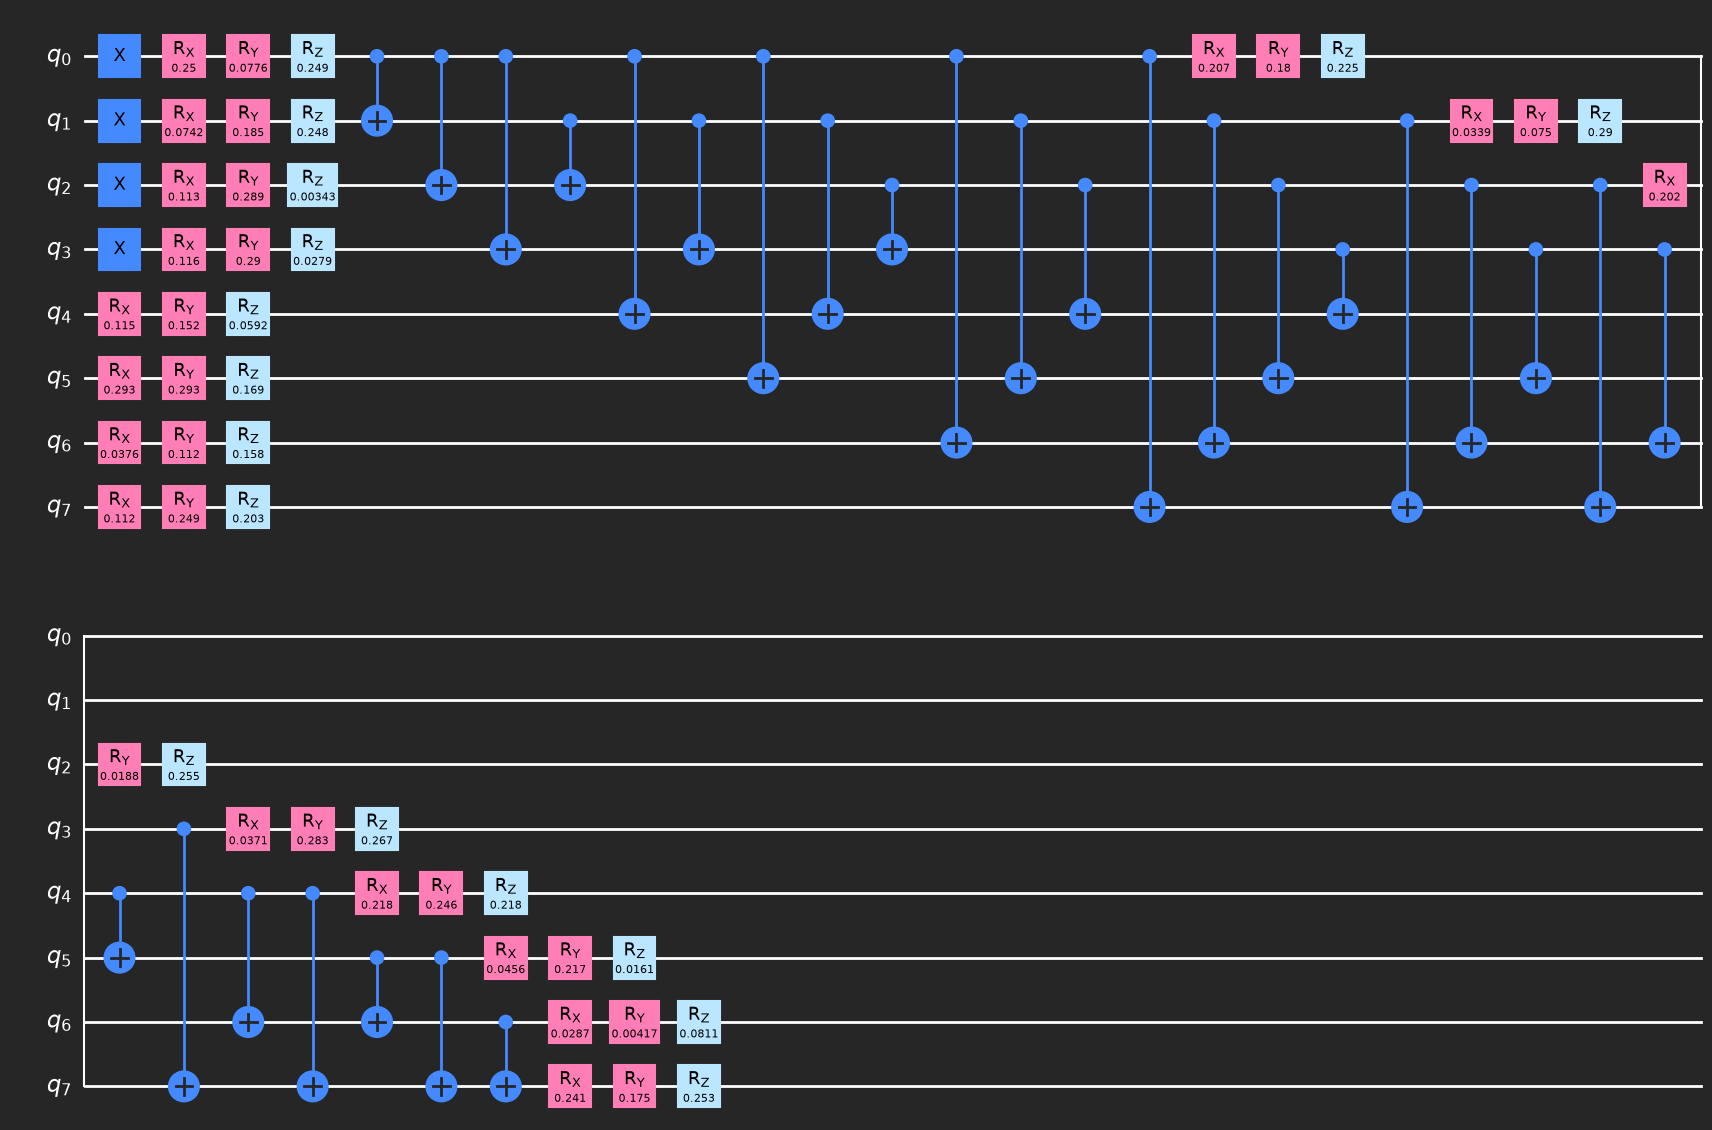

In [13]:
num_qubits = qiskit_H.num_qubits
num_electrons = qiskit_H.num_qubits // 2  # Assuming half-filling for simplicity

# Step 1: Hartree-Fock
qc = QuantumCircuit(num_qubits)
qc.x(range(num_electrons))

# Step 2: Add ansatz on top
params = np.random.uniform(0, 0.3, ansatz.num_parameters)  # SMALL angles

qc_bound = qc.compose(ansatz.assign_parameters(params))

print(ansatz.num_parameters, 'parameters in the ansatz, and', qc_bound.num_parameters, 'in the bound circuit')
draw_circuit(qc_bound)

That result confirms that all parameters are assigned and no symbolic parameters remain in the bound circuit.

In [14]:
energies = []

for shots in shots_list:
    counts = sample_counts_fixed(qc_bound, shots, sim = Aer.get_backend('aer_simulator'))
    
    E = run_sqd(counts, H)
    energies.append(E)

errors = [abs(E - E_exact) for E in energies]

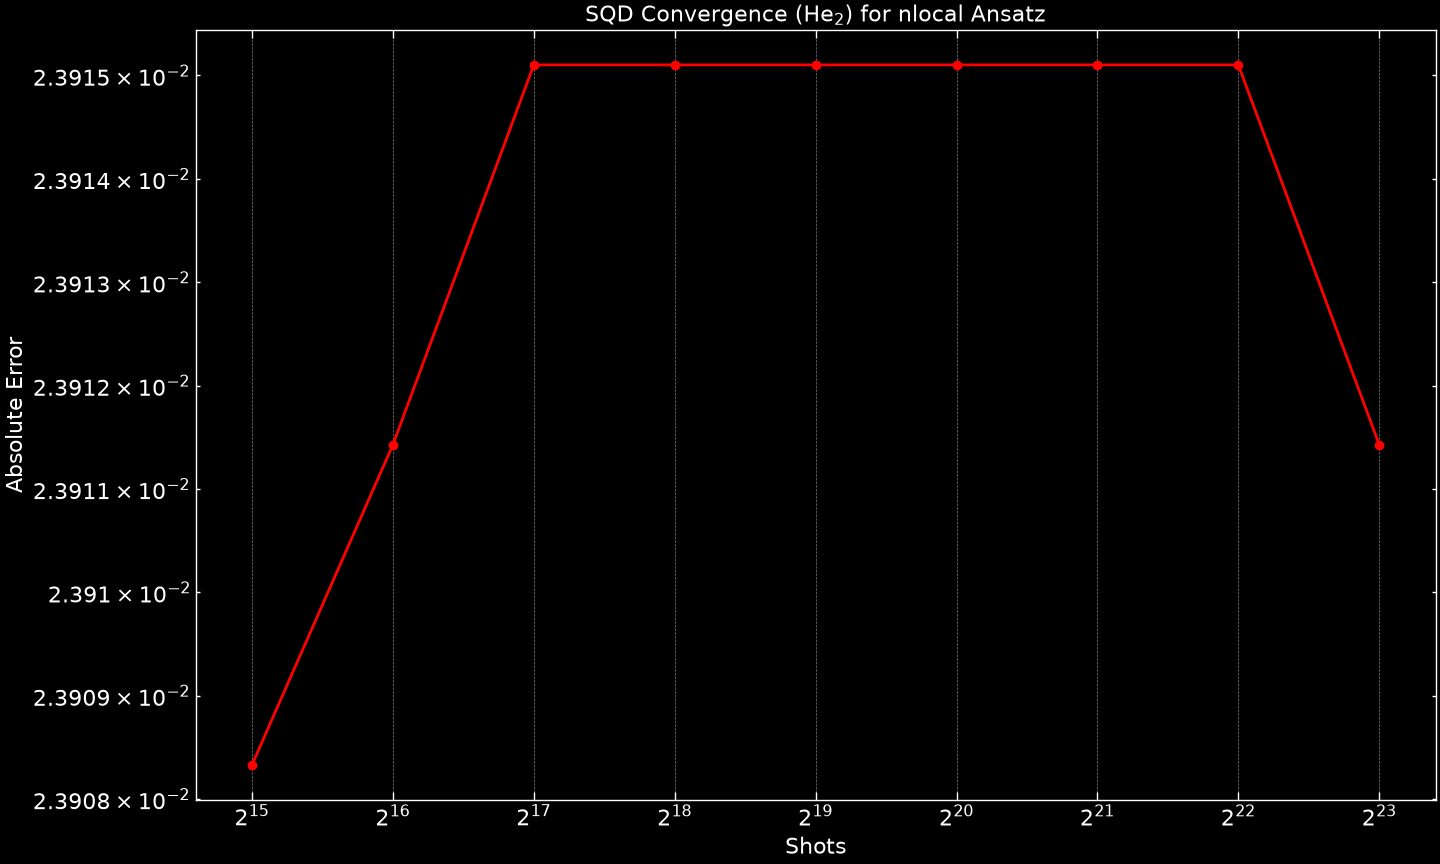

In [15]:
plt.figure(figsize = (16, 10))
plt.plot(shots_list, errors, color = 'r', marker = 'o')
plt.xscale('log', base = 2)
plt.yscale('log')

plt.xlabel('Shots')
plt.ylabel('Absolute Error')
plt.title(fr'SQD Convergence $(\text{{He}}_2)$ for {ansatz.name} Ansatz')
plt.grid(True)
plt.show()

In [16]:
print('SQD Energy', np.min(energies), "Hartrees, achieved with", shots_list[np.argmin(energies)], "shots", "with relative error", np.min(errors)/abs(E_exact))

SQD Energy -5.716415948462674 Hartrees, achieved with 32768 shots with relative error 0.00416497887294979


Based on your results, you can analyze how the estimated energy converges to the exact energy as you increase the number of shots, **IF** the sampled subspace includes configurations with significant overlap with the true ground state. SQD exhibits a threshold-like convergence behavior, and the accuracy, quite strangely improves abruptly once this condition is met. You might see sharp spikes (caused by subspace incompatibility or incompleteness) and plateaus (caused by insufficient subspace configurations) in the energy estimates as you increase the number of shots. The convergence can be quite non-monotonic, especially for small shot counts, due to the stochastic nature of the sampling process.

If you wanna test sampling error purely, you can run the same circuit on Aer and with a very high number of shots to get a near-exact distribution, and then feed those counts into the `run_sqd` function to see how close you get to the exact energy. This will give you a sense of how much of the error is due to sampling noise versus other factors like ansatz choice or Hamiltonian representation.

# Running on Hardware

In [17]:
service = QiskitRuntimeService(channel = 'ibm_cloud')
backend = service.least_busy(simulator = False, operational = True)
backend.name, backend.num_qubits

('ibm_marrakesh', 156)

Shot count and optimization level are the main levers to pull here, but keep in mind that the cost is just computational time, so you can do without compromising accuracy if you have the patience.

Also, if you want to change the parameters of your ansatz for the hardware run, you'd unfortunately need to re-run the entire process as variables could be modified. Just make sure to re-run the transpilation and measurement steps after changing the parameters, since the circuit will be different.

In [18]:
qc_bound.measure_all() # Remember, measure *before* transpilation
pm = generate_preset_pass_manager(backend = backend, optimization_level = 3)
qc_isa = pm.run(qc_bound)

Unles you'd like an anuerism, I'd recommend not plotting the counts :)

In [19]:
sampler = Sampler(mode = backend)
job = sampler.run([qc_isa], shots = 2 ** 19)

start = time.time()

while not job.in_final_state():
    
    status = job.status()
    elapsed = time.time() - start
    
    print(f'Status: {status} | Elapsed: {elapsed:.1f} s', end = '\r')
    time.sleep(2)   # check every 2s

result = job.result()
elapsed_total = time.time() - start

print(f'\n✅ Job finished in {elapsed_total:.1f} s | Final status: {job.status()}')
counts = next(iter(result[0].data.values())).get_counts()

Status: DONE | Elapsed: 229.9 s2 s
✅ Job finished in 233.1 s | Final status: DONE


In [20]:
E = run_sqd(counts, H)
print('SQD Energy from hardware:', E, "Hartrees, with relative error", abs(E - E_exact)/abs(E_exact))

SQD Energy from hardware: -5.724201120516036 Hartrees, with relative error 0.0028087537406057453


# And That's It!

More advanced variants of SQD iteratively refine the sampled subspace, but we restrict ourselves to a single-pass implementation to emphasize the core idea.

# Bonus: Krylov-based SQD

I wouldn't blame you if you decided to take a break from this, I admit it is a bit heavy on the conceptual side, but if you're still with me, let's briefly touch on *Krylov-based SQD*, which is a more sophisticated method that introduces a Krylov subspace to improve the accuracy of the diagonalization. Now what is that?

In linear algebra, a Krylov subspace is generated by repeatedly applying a matrix (in our case, the Hamiltonian) to a vector (our initial state). More formally, An $r$-ordered Krylov subspace generated by a size $n \times n$ matrix $A$ and a vector $v$ (of dimension $n$) is defined as the linear subspace spanned by $$\mathcal{K}_r(A, v) = \text{span}\{v, Av, A^2v, \ldots, A^{r-1}v\}$$ If this seems heavy, just think of it as a way to build a subspace that captures the action of the Hamiltonian on our initial state, which we can iterate over to better approximate the ground state. So instead of sampling from just the original state prepared by our ansatz, we can also include the set of 'Hamiltonian-evolved' states generated by applying powers of $\mathscr {\hat H}$ to our initial state.

Given the diagonalizable Hamiltonian $\mathscr{\hat H}$ and an initial state $\ket{\psi_0}$, we can construct the Krylov subspace $\mathcal{K}_r(\mathscr{\hat H}, \ket{\psi_0})$ and then project the Hamiltonian onto this subspace to obtain a smaller matrix representation, say $\mathscr{\hat H}_r$. 

# Getting Started:

Let me just outline the workflow for you, but I won't go into the details of the implementation here, as it can get quite involved. The main idea is to use the Krylov subspace to iteratively refine our approximation of the ground state energy and wavefunction. We start with our initial state $\ket{\psi_0}$, and then we apply the Hamiltonian to generate new states that span the Krylov subspace. In practice, this is not done by explicitly applying the Hamiltonian, but rather by using the measurement data to construct the necessary matrix elements and then performing the projection and diagonalization steps **classically.** 

Then, we **iteratively** expand the Krylov subspace by including higher powers of the Hamiltonian applied to our initial state, and at each iteration, we project the Hamiltonian onto the expanded subspace and diagonalize it to get improved estimates of the ground state energy and wavefunction. This iterative process continues until convergence is achieved, meaning that further expansions of the Krylov subspace do not significantly change the estimated ground state energy. You might have seen this workflow in the context of classical algorithms for eigenvalue problems, and it's for good reason, as it's quite powerful for improving the accuracy of our estimates without needing to increase the size of the sampled subspace too much.

Just a side note on why we're doing this this way; if I was crazy enough to implement KSQD classically, I would have to explicitly construct the Krylov subspace by applying the Hamiltonian to our initial state and then orthogonalizing the resulting states to get an orthonormal basis for the subspace. Remember, Krylov spaces are not necessarily orthogonal, so we would need to perform a Gram-Schmidt process or something similar to ensure we have an orthonormal basis before projecting the Hamiltonian and diagonalizing it.

This can of course be ridiculously computationally expensive, especially for large molecules, which is why we rely on classical methodsa only for measurement data and post-processing. We could also use VQE or QPE, but as we've seen, VQE can be quite finicky and QPE is still out of reach for most practical applications, so KSQD offers a nice middle ground where we can leverage the power of quantum sampling while still using classical resources for the heavy lifting of diagonalization.

Now, as the Krylov subspace is non-diagonal, we need to perform a similarity transformation to diagonalize the projected Hamiltonian. This involves finding a **unitary transformation** that diagonalizes the matrix representation of the Hamiltonian in the Krylov subspace, so we could enforce $$\text{span}({\mathscr{\hat U}})=\text{span}\big({\mathcal{K}_r(\mathscr{\hat H}, \ket{\psi_0})}\big)$$ where $\mathscr{\hat U}=\exp(i\mathscr{\hat H}t)$ is the unitary transformation that diagonalizes the projected Hamiltonian. Expand $\mathscr{\hat U}$ in its Taylor series to get a linear combination of powers of the Hamiltonian, and you'll see exactly why this is the case. (Hint: $\mathscr{\hat U}$ is **polynomial in $\mathscr{\hat H}$**)



# The Workflow

First, we (initialize, then) generate Krylov states $\ket{\psi_k} = \mathscr{\hat U}^k \ket{\psi_0}\equiv\exp(i\mathscr{\hat H}t_k)\ket{\psi_0}$ for $k=0,1,\ldots,r-1$ and $t_k=k\delta t$, where $\ket{\psi_0}$ is our initial state prepared by the ansatz. Remember, $\mathscr{\hat H}$ is interchangeable with $\mathscr{\hat U}$ (think of the 'generator' versus the 'fluid'). Then, we can reuse your molecular Hamiltonian and project it onto the Krylov subspace spanned by these states to get a smaller matrix representation of $\mathscr{\hat H_r}$.

In [21]:
basis = set()
energies = []

qiskit_H

SparsePauliOp(['IIIIIIII', 'IIIIIIIZ', 'IIIIIIZI', 'IIIIIIZZ', 'IIIIIZII', 'IIIIIZIZ', 'IIIIIZZI', 'IIIIXXYY', 'IIIIXYYX', 'IIIIYXXY', 'IIIIYYXX', 'IIIIZIII', 'IIIIZIIZ', 'IIIIZIZI', 'IIIIZZII', 'IIIXIZZX', 'IIIXXYYI', 'IIIXYYXI', 'IIIXZZIX', 'IIIXZZZX', 'IIIYIZZY', 'IIIYXXYI', 'IIIYYXXI', 'IIIYZZIY', 'IIIYZZZY', 'IIIZIIII', 'IIIZIIIZ', 'IIIZIIZI', 'IIIZIZII', 'IIIZZIII', 'IIXIZZXI', 'IIXXIIYY', 'IIXXYYII', 'IIXYIIYX', 'IIXYYXII', 'IIXZXXZX', 'IIXZXYZY', 'IIXZZIXI', 'IIXZZZXI', 'IIXZZZXZ', 'IIYIZZYI', 'IIYXIIXY', 'IIYXXYII', 'IIYYIIXX', 'IIYYXXII', 'IIYZYXZX', 'IIYZYYZY', 'IIYZZIYI', 'IIYZZZYI', 'IIYZZZYZ', 'IIZIIIII', 'IIZIIIIZ', 'IIZIIIZI', 'IIZIIZII', 'IIZIZIII', 'IIZXZZZX', 'IIZYZZZY', 'IIZZIIII', 'IXIZZXII', 'IXXIIYYI', 'IXXIXZZX', 'IXXYYIII', 'IXYIIYXI', 'IXYIYZZX', 'IXYYXIII', 'IXZXIXZX', 'IXZXIYZY', 'IXZXXZXI', 'IXZXYZYI', 'IXZZIXII', 'IXZZXIXX', 'IXZZYIYX', 'IXZZZXII', 'IXZZZXZI', 'IYIZZYII', 'IYXIIXYI', 'IYXIXZZY', 'IYXXYIII', 'IYYIIXXI', 'IYYIYZZY', 'IYYXXIII', 'IYZYIXZX', '

Setting $\delta t$ is a bit of an art, but it should be small enough to ensure that the **phases** resolve nicely along the unit circle, so that the Krylov states are sufficiently distinct. Try to find such a value. Enforce $$\|\mathscr{\hat H}\| =\text{max}(E_k)\implies E_k\in\mp\,\|\mathscr{\hat H}\|$$ and you should get

In [22]:
dt = np.pi / (np.linalg.norm(qiskit_H, ord = 2))
times = np.arange(0, 10 * dt, dt)

dt, times

(np.float64(0.5472848747826661),
 array([0.        , 0.54728487, 1.09456975, 1.64185462, 2.1891395 ,
        2.73642437, 3.28370925, 3.83099412, 4.378279  , 4.92556387]))

Now for the time-evolved Krylov states, we can of course use `qc_bound`, but recall that it was **measured** when we first defined it. We hence need to start with a fresh circuit and apply the time evolution gate, and **then measure**. Remember, you can redefine the ansatz and other parameters to personalize the workflow, but make sure to re-run thereon if you do so, as the parameters could be modified.

48 parameters in the ansatz, and 0 in the bound circuit


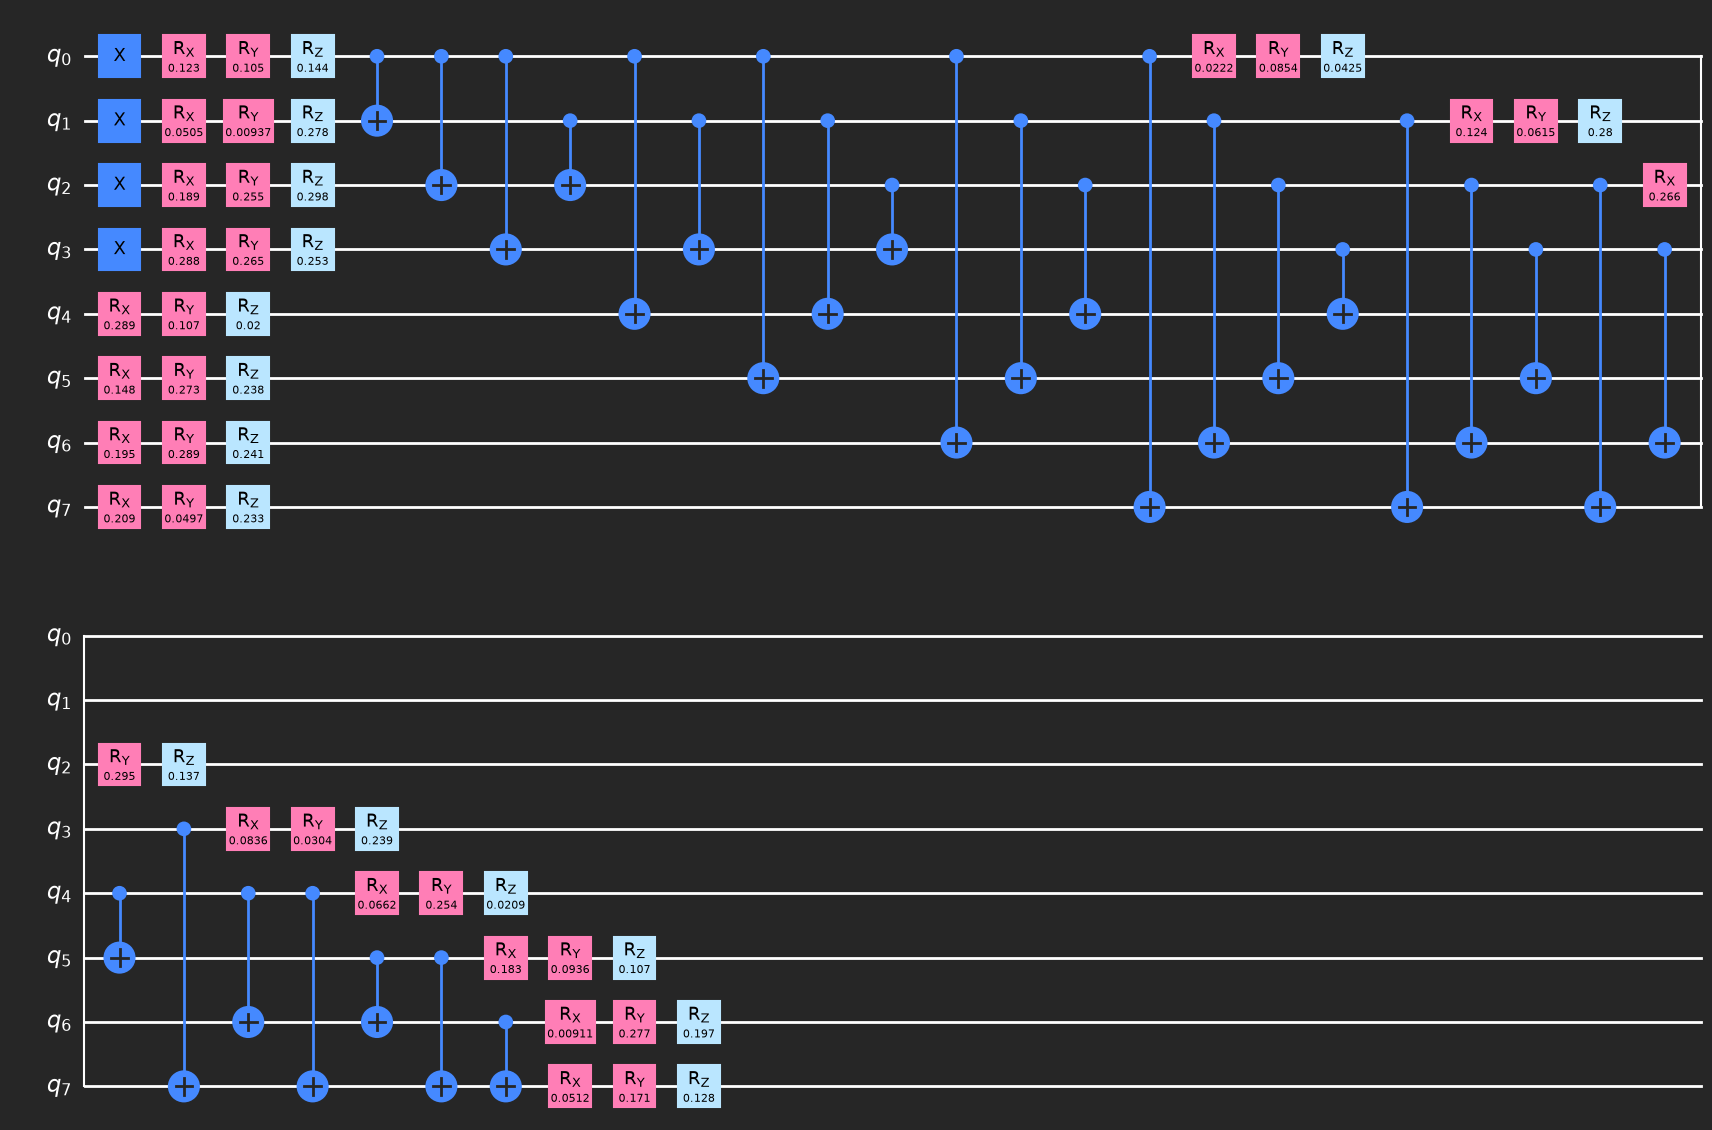

In [23]:
ansatz = ansatzes['EfficientSU2']

# Step 1: Hartree-Fock
qc = QuantumCircuit(num_qubits)
qc.x(range(num_electrons))

# Step 2: Add ansatz on top
params = np.random.uniform(0, 0.3, ansatz.num_parameters)  # SMALL angles

qc_bound = qc.compose(ansatz.assign_parameters(params))

print(ansatz.num_parameters, 'parameters in the ansatz, and', qc_bound.num_parameters, 'in the bound circuit')
draw_circuit(qc_bound)

Now, I can just feed in the time-evolved parameters to get the corresponding states, and then we can construct the projected Hamiltonian matrix by computing the matrix elements $\langle \psi_i | \mathscr{\hat U} | \psi_j \rangle$ for all Krylov pairs. `PauliEvolutionGate` is your friend here, as it allows you to implement the time evolution under the Hamiltonian directly in `qc_bound`, so you can easily generate the necessary states for the Krylov subspace.

Remember, the sequence goes as $\{\ket{\psi_0}, \exp(i\mathscr{\hat H}dt)\ket{\psi_0}, \exp(i\mathscr{\hat H}2dt)\ket{\psi_0}, \ldots\}$, as $t_k=k\delta t$. Also, remember that measurement always comes at the end of the circuit, before time-evolution.

In [24]:
t = Parameter('t')
U = PauliEvolutionGate(qiskit_H, time = t)

qc = qc_bound.copy()
qc.append(U, range(qc.num_qubits))

In [25]:
circuits = [qc.assign_parameters({t: val}) for val in times]

Now to sample counts from each of these circuits. We'll run on Aer first, as the APIs for sampling on hardware can be a bit different:

In [26]:
all_counts = []

for qi in circuits:
    
    counts = sample_counts_fixed(qi, shots = 2 ** 19, sim = Aer.get_backend('aer_simulator')) # You can change shots or include noise model if you desire
    all_counts.append(counts)

for counts in all_counts:
    
    new_basis = get_basis_states_topk(counts, k = 100) # You can also modify k here, but keep in mind the classical diagonalization cost
    basis.update(new_basis)

all_counts

[{'11111110': 1,
  '11110111': 2,
  '10100000': 1,
  '00100110': 1,
  '11000011': 1,
  '10110111': 1,
  '01001000': 1,
  '01000111': 1,
  '01110110': 1,
  '11010110': 5,
  '11100010': 1,
  '10011100': 1,
  '10001011': 1,
  '11000111': 2,
  '10110010': 4,
  '01010110': 2,
  '01001011': 1,
  '01110100': 1,
  '01001010': 2,
  '00000110': 3,
  '11101011': 1,
  '01111100': 1,
  '01010000': 9,
  '01000010': 1,
  '00000100': 3,
  '11011001': 5,
  '00101011': 1,
  '10110011': 2,
  '01110111': 13,
  '01011100': 1,
  '00000111': 12,
  '11111111': 1,
  '11001101': 10,
  '11100101': 7,
  '01011001': 5,
  '10000101': 13,
  '00100000': 14,
  '10111001': 5,
  '01100101': 4,
  '00101000': 1,
  '11101101': 11,
  '00110111': 10,
  '00000000': 13,
  '00110011': 22,
  '01110000': 17,
  '10101101': 13,
  '11011100': 1,
  '10011111': 4,
  '00100011': 34,
  '11111001': 20,
  '00001100': 1,
  '00001110': 2,
  '01000000': 1,
  '01110010': 71,
  '10010000': 18,
  '00011100': 23,
  '01111110': 4,
  '11000101': 2

And now to feed our basis into the `projected_hamiltonian` function to run the SQD workflow. Note that we **can't** directly feed in the counts in `run_sqd`, as it expects a matrix representation of the Hamiltonian in the Krylov subspace, so we need to first construct that matrix using the sampled data and then pass it to `run_sqd` to get our estimated ground state energy:

In [27]:
basis_list = list(basis)
basis_indices = bitstrings_to_indices(basis_list)

H_sub = project_hamiltonian(H, basis_indices)
basis_indices, H_sub
print("Subscpace dimension:", len(basis_indices), "({}% of the full space)".format(100 * len(basis_indices) / 2 ** num_qubits))

Subscpace dimension: 179 (69.921875% of the full space)


There's no determinable rule of thumb for an ideal Hilbert space utilization, but a sweet spot based pon my reruns would probabily be around 50-60% of the full space. The KSQD accuracy can of course, also be improved by increasing the number of shots and $k$-value. Quick sanity checks:

In [28]:
print(H_sub.shape)
print(np.allclose(H_sub, H_sub.conj().T))  # should be True

(179, 179)
True


Now we can diagonalize classically, no problem:

In [29]:
E = np.linalg.eigvalsh(H_sub)[0]
print("Krylov-SQD Energy:", E, "Hartrees, with relative error", abs(E - E_exact)/abs(E_exact))

Krylov-SQD Energy: -5.74032427780387 Hartrees, with relative error 4.5798947848261555e-14


Let's do a convergence test with hardware:

In [30]:
service = QiskitRuntimeService(channel = 'ibm_cloud')
backend = service.least_busy(simulator = False, operational = True)
backend.name, backend.num_qubits

('ibm_marrakesh', 156)

As methods and defined functions vary in API and implementation, I won't be able to replicate the Aer workflow as-is, so this is the messy codeblock that still works:

In [31]:
measured_circuits = []

for qi in circuits:

    qi_m = qi.copy()
    qi_m.measure_all()
    measured_circuits.append(qi_m)

pm = generate_preset_pass_manager(optimization_level = 3, backend = backend)
circuits_isa = [pm.run(qc) for qc in measured_circuits]
sampler = Sampler(mode = backend)

In [32]:
energies = []
shots_list = [2 ** k for k in range(10, 15)]
k = 100

for shots in shots_list:
    
    print(f"\nRunning for shots = {shots}...")

    start = time.time()
    
    job = sampler.run(circuits_isa, shots = shots)
    result = job.result()
    
    all_counts = []
    
    for pub_result in result:
        data_bin = pub_result.data
        quasi = next(iter(data_bin.values()))
        
        if hasattr(quasi, "get_counts"):
            counts = quasi.get_counts()
        
        else:
            counts = quasi.to_counts()
        
        all_counts.append(counts)
    
    basis = set()
    
    for counts in all_counts:
        basis.update(get_basis_states_topk(counts, k=k))
    
    idx = bitstrings_to_indices(list(basis))
    H_sub = project_hamiltonian(H, idx)
    
    E = np.linalg.eigvalsh(H_sub)[0]
    energies.append(E)
    
    end = time.time()
    print(f"For {shots} shots E = {E} Hartrees, in time {end - start} seconds", "with relative error", abs(E - E_exact)/abs(E_exact))


Running for shots = 1024...
For 1024 shots E = -5.740324277740893 Hartrees, in time 71.00378799438477 seconds with relative error 1.0925215228262663e-11

Running for shots = 2048...
For 2048 shots E = -5.740324277740881 Hartrees, in time 27.931409120559692 seconds with relative error 1.0927226668539783e-11

Running for shots = 4096...
For 4096 shots E = -5.740324277740886 Hartrees, in time 26.124927043914795 seconds with relative error 1.0926453037663967e-11

Running for shots = 8192...
For 8192 shots E = -5.740316093261754 Hartrees, in time 63.69988822937012 seconds with relative error 1.4257978220477321e-06

Running for shots = 16384...
For 16384 shots E = -5.740316093261754 Hartrees, in time 120.28223824501038 seconds with relative error 1.4257978220477321e-06


Let's plot the convergence behavior and an error heatmap:

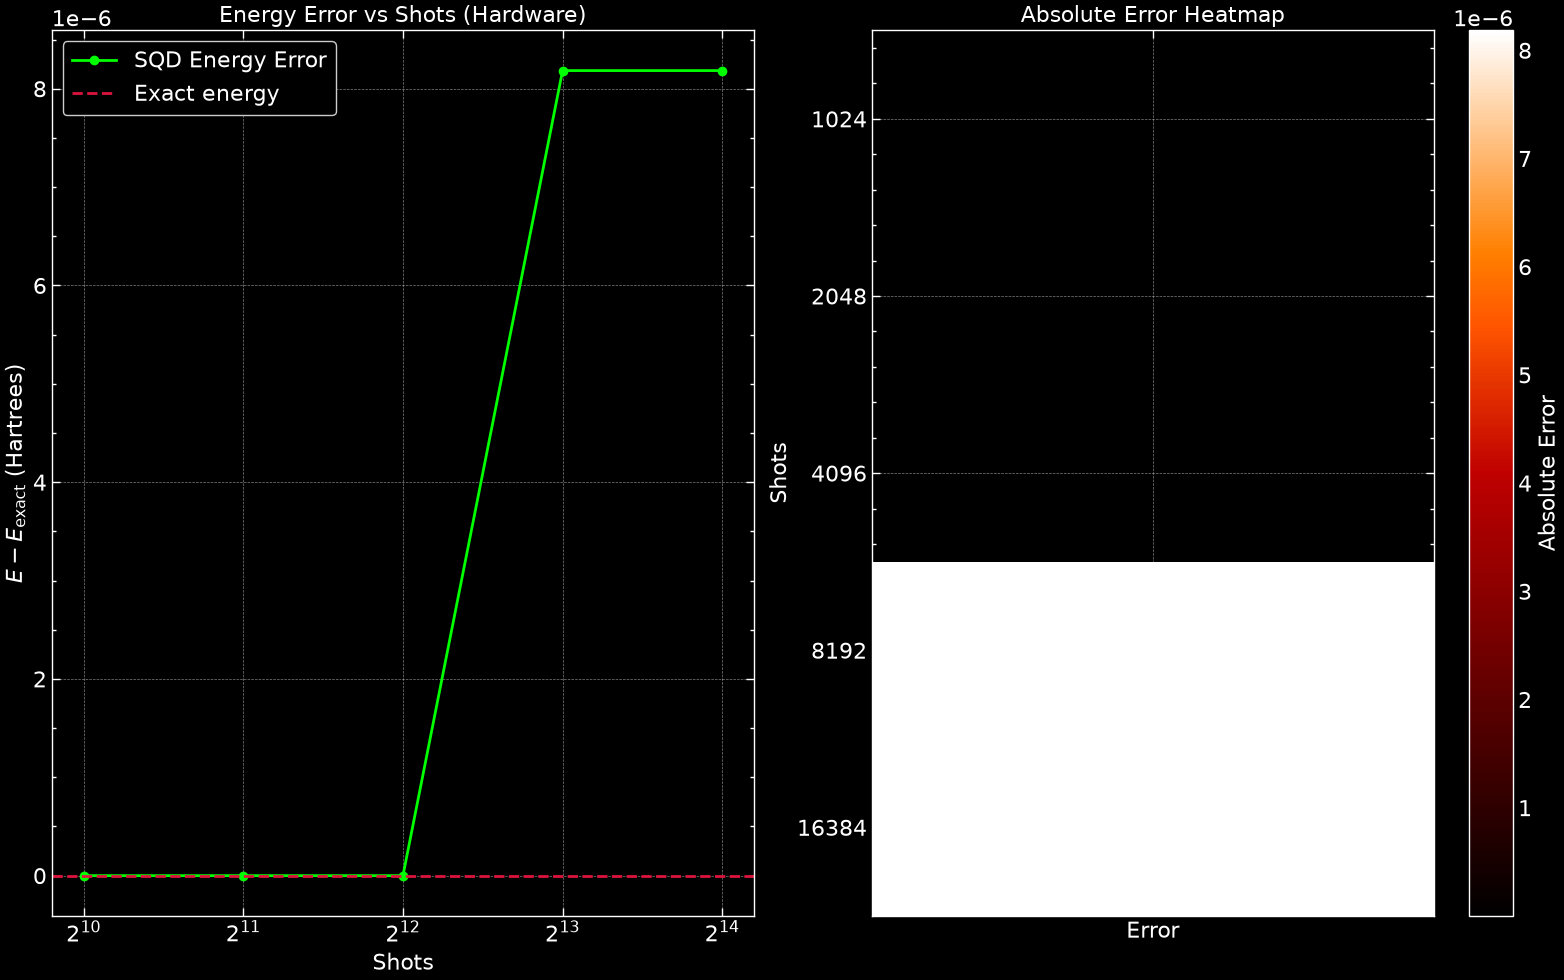

In [33]:
errors = [abs(E - E_exact) for E in energies]
heatmap_data = np.array(errors).reshape(-1, 1)

fig, axes = plt.subplots(1, 2, figsize = (16, 10))

# Energy error vs Shots
axes[0].plot(shots_list, errors, marker = 'o', color = 'lime', linewidth = 2, label = 'SQD Energy Error')
axes[0].axhline(0, linestyle = '--', color = 'crimson', label = 'Exact energy')

axes[0].set_xscale('log', base = 2)

axes[0].set_title("Energy Error vs Shots (Hardware)")
axes[0].set_xlabel("Shots")
axes[0].set_ylabel(r"$E - E_{\mathrm{exact}}$ (Hartrees)")

axes[0].legend()
axes[0].grid(True)

# Heatmap of Error
im = axes[1].imshow(heatmap_data, aspect = 'auto', cmap = 'gist_heat')

axes[1].set_yticks(range(len(shots_list)))
axes[1].set_yticklabels(shots_list)
axes[1].set_xticks([0])
axes[1].set_xticklabels(['Error'])

axes[1].set_ylabel("Shots")
axes[1].set_title("Absolute Error Heatmap")

# colorbar (attached to heatmap)
fig.colorbar(im, ax = axes[1], label = "Absolute Error")

plt.tight_layout()

Aaaand we're done! This was a pretty heavy notebook, so take a breath, and feel free to explore the code and tweak the parameters to see how it affects the results. I'll see you in the next one!